In [1]:
# Breast Cancer Prediction with KNN
# Author: Roodabeh Seif

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Load data: 0 = malignant, 1 = benign
cancer_data = load_breast_cancer()

df = pd.DataFrame(
    cancer_data.data,
    columns=cancer_data.feature_names
)
df["target"] = cancer_data.target

print("Number of samples:", len(df))
print("Number of features:", len(cancer_data.feature_names))
print("\nClass labels:", dict(enumerate(cancer_data.target_names)))

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nTarget distribution:")
print(df["target"].value_counts())
print("Malignant (0):", (df["target"] == 0).sum())
print("Benign (1):", (df["target"] == 1).sum())

Number of samples: 569
Number of features: 30

Class labels: {0: np.str_('malignant'), 1: np.str_('benign')}

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness erro

### Step 1 — Observations
The dataset contains 569 samples and 30 numeric features.
There are 212 malignant cases (0) and 357 benign cases (1).
Benign cases are more common, so the classes are not equally balanced.

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


Total missing values: 0


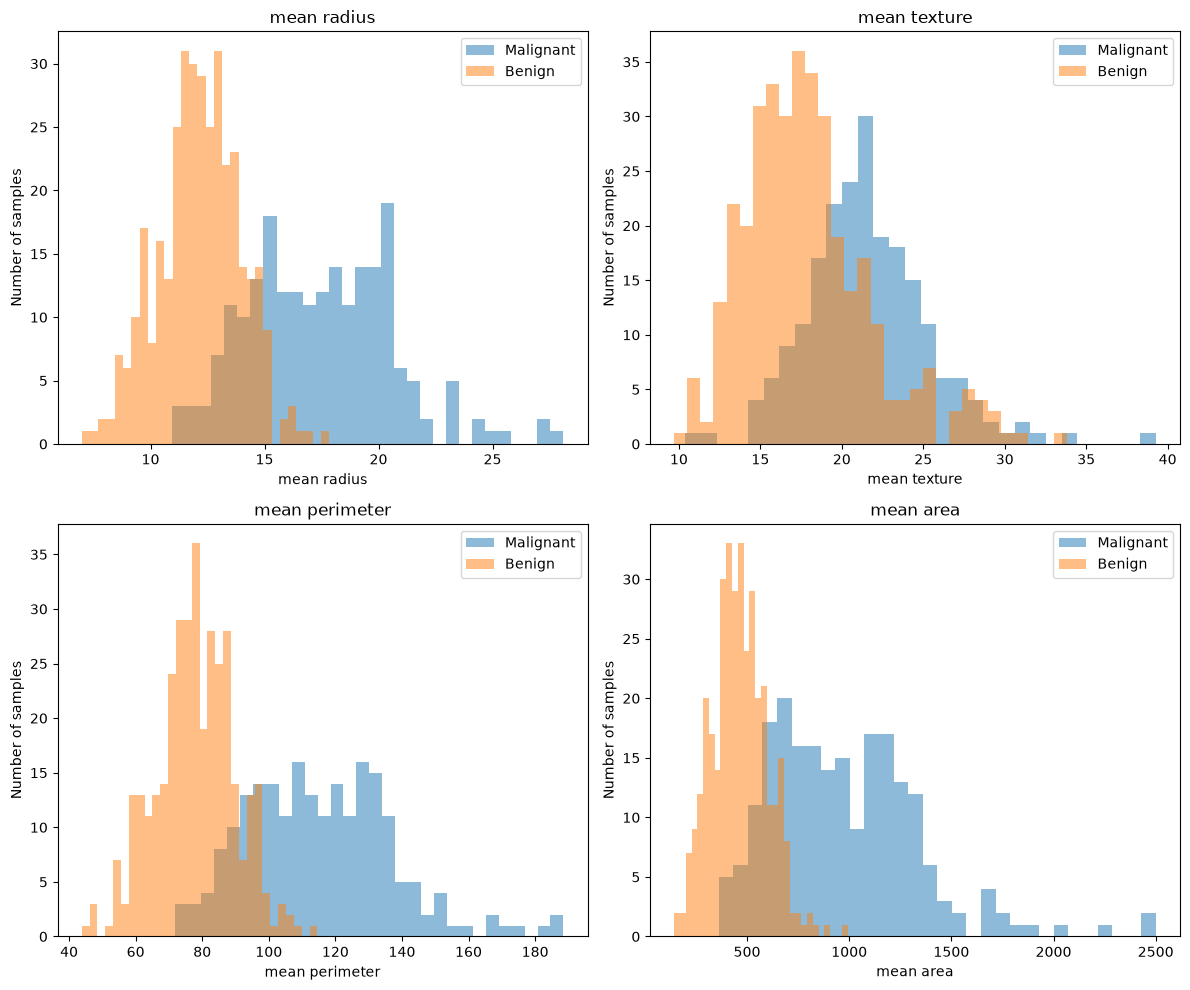

In [2]:
# Step 2: Summary statistics and missing values
display(df.describe())

missing = df.isnull().sum()
print("Total missing values:", missing.sum())

# Compare feature distributions using the correct class labels
key_features = [
    "mean radius", "mean texture", "mean perimeter", "mean area"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, feature in zip(axes.ravel(), key_features):
    ax.hist(
        df.loc[df["target"] == 0, feature],
        bins=30, alpha=0.5, label="Malignant"
    )
    ax.hist(
        df.loc[df["target"] == 1, feature],
        bins=30, alpha=0.5, label="Benign"
    )
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of samples")
    ax.legend()

plt.tight_layout()
plt.savefig("feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
# Step 3: Separate inputs from the answer
X = df.drop(columns="target")
y = df["target"]

# Keep 20% of the samples for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

distribution = pd.DataFrame({
    "Training count": y_train.value_counts(),
    "Test count": y_test.value_counts(),
    "Training %": y_train.value_counts(normalize=True) * 100,
    "Test %": y_test.value_counts(normalize=True) * 100
})
distribution.index = distribution.index.map({
    0: "Malignant",
    1: "Benign"
})
display(distribution.round(1))

Training samples: 455
Test samples: 114


,Training count,Test count,Training %,Test %
target,,,,
Benign,285,72,62.6,63.2
Malignant,170,42,37.4,36.8


In [4]:
# Step 4: Train the KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

print("KNN classifier trained successfully!")
print("Number of neighbors:", knn.n_neighbors)


KNN classifier trained successfully!
Number of neighbors: 5


In [5]:
# Step 5: Make predictions
y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)

comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_test_pred
})

comparison["Correct"] = comparison["Actual"] == comparison["Predicted"]
comparison["Actual"] = comparison["Actual"].map({
    0: "Malignant", 1: "Benign"
})
comparison["Predicted"] = comparison["Predicted"].map({
    0: "Malignant", 1: "Benign"
})

display(comparison.head(10))

,Actual,Predicted,Correct
256,Malignant,Malignant,True
428,Benign,Benign,True
501,Malignant,Malignant,True
363,Benign,Malignant,False
564,Malignant,Malignant,True
464,Benign,Benign,True
358,Benign,Benign,True
343,Malignant,Malignant,True
516,Malignant,Malignant,True
567,Malignant,Malignant,True


In [6]:
# Step 6: Evaluate performance
# Malignant is class 0, so use pos_label=0.
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(
    y_test, y_test_pred, pos_label=0
)
test_recall = recall_score(
    y_test, y_test_pred, pos_label=0
)

print(f"Training accuracy: {train_accuracy:.2%}")
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Malignant precision: {test_precision:.2%}")
print(f"Malignant recall: {test_recall:.2%}")

test_confusion = confusion_matrix(
    y_test, y_test_pred, labels=[0, 1]
)

print("\nConfusion matrix:")
display(pd.DataFrame(
    test_confusion,
    index=["Actual malignant", "Actual benign"],
    columns=["Predicted malignant", "Predicted benign"]
))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["Malignant", "Benign"]
))

Training accuracy: 94.73%
Test accuracy: 91.23%
Malignant precision: 86.36%
Malignant recall: 90.48%

Confusion matrix:


,Predicted malignant,Predicted benign
Actual malignant,38,4
Actual benign,6,66



Classification report:
              precision    recall  f1-score   support

   Malignant       0.86      0.90      0.88        42
      Benign       0.94      0.92      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.91      0.91       114
weighted avg       0.91      0.91      0.91       114



,K,Accuracy,Precision,Recall
0,1,0.9211,0.8667,0.9286
1,3,0.9298,0.9048,0.9048
2,5,0.9123,0.8636,0.9048
3,7,0.9298,0.9048,0.9048
4,9,0.9386,0.9268,0.9048
5,11,0.9386,0.9268,0.9048


Highest test accuracy at K = 9
Test accuracy: 93.86%


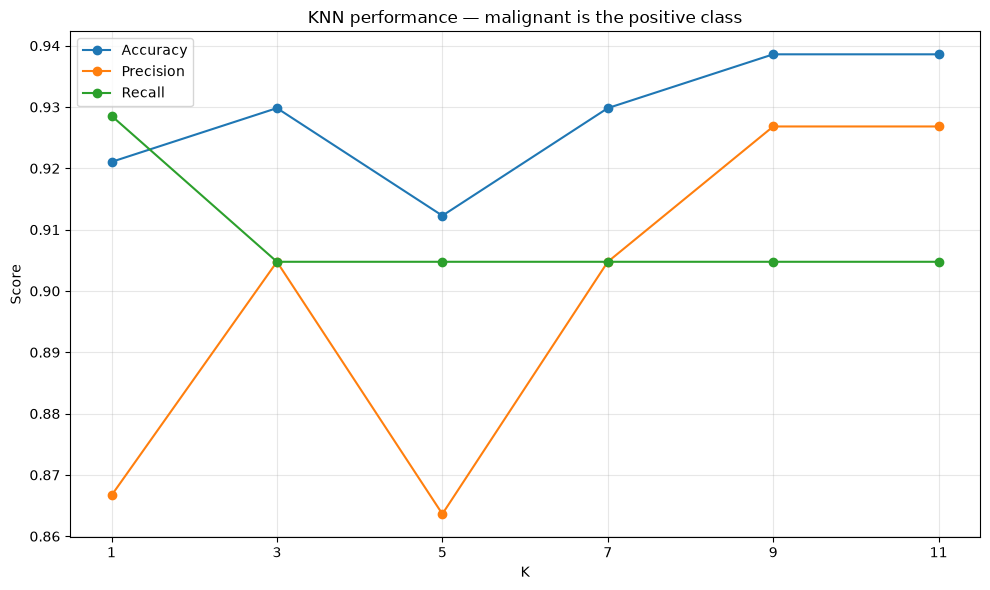

In [7]:
# Step 7: Compare different K values
k_values = [1, 3, 5, 7, 9, 11]
results = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "K": k,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, pos_label=0, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, pos_label=0, zero_division=0
        )
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

best_row = results_df.loc[results_df["Accuracy"].idxmax()]
print("Highest test accuracy at K =", int(best_row["K"]))
print(f"Test accuracy: {best_row['Accuracy']:.2%}")

results_df.plot(
    x="K",
    y=["Accuracy", "Precision", "Recall"],
    marker="o",
    figsize=(10, 6)
)
plt.title("KNN performance — malignant is the positive class")
plt.ylabel("Score")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("knn_k_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Steps 3–7 — Observations

The data was split into 455 training samples and 114 test samples.
Stratification preserved similar class proportions in both sets.

The KNN model uses the five nearest training samples to classify
a new sample by majority vote.

Predictions were compared with the actual labels.
Precision and recall were calculated for malignant cases (class 0).
Recall measures how many malignant cases the model detects.

Different K values were compared in the table and plot above.
The highest test accuracy does not necessarily give the highest
malignant recall.

Limitations:
- Features were not scaled, so larger-scale features can dominate distances.
- Comparing K values on the test set can make the selected result optimistic.
- Future improvements include scaling and cross-validation on training data.